# 02. Machine Learning: PerfectPetClub Churn Prediction (PySpark MLlib)

**Module:** 7COM2005 - Data Engineering, University of Hertfordshire

**Input:** `data/processed/customer_churn_dataset.parquet` (canonical ETL output, 221 customers x 36 columns).
The mock CSV copies and the team's pickle model are **not** used anywhere in this notebook.

**Environment:** Python 3.12, PySpark 4.3.0, pandas 2.3.x (pandas 3 is not yet supported by PySpark). All modelling uses PySpark MLlib; scikit-learn is not used in this notebook.
Java 17 or 21 must be installed for Spark.

**Target:** `churn_label = 1 - auto_renew`. Positive class = churn (did not renew).

> **⚠ PREDICTION-TIME LEAKAGE LIMITATION - READ FIRST**
>
> The ETL features in the Parquet are aggregated over each customer's *whole* subscription window (`start_date` to `end_date`). For churned customers that window ends at cancellation, so the features include activity close to the outcome. Churned customers also have shorter windows (median 90 days against 180), which makes count and total features smaller for them by construction.
>
> **Consequence:** the metrics below (Configurations A and B) are *not* a valid forecast of renewal made before the decision. Configuration S, which removes tenure and raw totals, falls to near-chance performance (test AUC 0.55 to 0.58), which shows how much of the apparent signal depends on these features.
>
> The ETL has **not** been changed. A leakage-controlled version is in [03_Fixed_Cutoff_Features.ipynb](03_Fixed_Cutoff_Features.ipynb) and [04_Cutoff_Machine_Learning.ipynb](04_Cutoff_Machine_Learning.ipynb). It uses only events before start + 14 days, and its results are much weaker (CV AUC 0.48 to 0.60). Treat every number in this notebook as a diagnostic of the full-window features, not as a valid forecast. Design: [fixed_cutoff_feature_design.md](../documentation/fixed_cutoff_feature_design.md).

## Design decisions

| Decision | Choice | Why |
|---|---|---|
| Positive class | `churn_label = 1 - auto_renew` | Churn is the event we want to detect; precision, recall and F1 are reported for churn. |
| Split | Exact stratified 80/20, seed 42 | Keeps the 61/39 class ratio in both sets. The test set is only about 44 customers, so every metric is noisy. |
| Oversampling | None | Done after splitting it would leak; the imbalance is mild (39% churn). |
| Preprocessing | `StringIndexer` (handleInvalid=keep) -> `OneHotEncoder` -> `Imputer(median)` -> `VectorAssembler` -> `StandardScaler` | All stages are inside a `Pipeline`, so they are fitted on the training fold only. |
| Missing average rating | Set `avg_star_rating` to null where `has_reviews = 0`, keep `has_reviews` as a feature, impute the median from training data | The ETL filled these customers with 3.0, which is an invented rating. |
| Scaler | `withMean=False` | Mean-centring a sparse vector fails in Spark; scaling by standard deviation is enough for these models. |
| Model selection | 3-fold `CrossValidator` on the training set, maximising area under ROC | ROC-AUC is threshold-free and more stable than F1 with about 177 training rows. Test data is never used for choosing parameters. |
| Final model choice | Highest CV AUC among Configurations A and B | Chosen before looking at test results. |
| Models | LogisticRegression, RandomForestClassifier, GBTClassifier | All three are PySpark MLlib models, as the assignment requires. |
| Grids | Small (2 to 6 combinations per model) | The dataset has 221 rows. |

## Investigation findings (before preprocessing)

### Verified from files and data

1. **Parquet:** 221 rows, 36 columns, 0 nulls, unique `customer_id`, `auto_renew` 135 renewed / 86 not renewed.
2. **Survey file:** 221 rows, 0 nulls, all three 0-10 scores present for every respondent, all 221 emails unique. The ETL did no imputation on survey values, so any 0 in the Parquet is a raw survey value.
3. **Survey zeros:** `satisfaction_score` has 29 zeros, `nps_recommend` has 2, `online_comparison_freq` has 1. No customer has zeros on all three scores. The zeros are not a spike against neighbouring values: 1, 2 and 3 each have about 23 responses, and 4 has 8.
4. **Questionnaire wording error:** the questionnaire gives Q2 (`nps_recommend`) and Q3 (`satisfaction_score`) the same question text, "Would you recommend us to a friend?". So `satisfaction_score` is of unclear construct, and interpreting it needs care.
5. **No survey timestamps:** the survey file has no date column. The questionnaire says it was a web-app popup for logged-in customers.
6. **ETL window:** every feature is aggregated over the full subscription window (`start_date` to `end_date`). I checked the SQLite database read-only: no orders fall before the start or after the end date for any customer.
7. **Churn timing:** `end_date` for churned subscriptions is the cancellation date, so the window for churned customers stops at cancellation. Churned customers have a median `duration_days` of 90 against 180 for renewed customers. The mean of `total_orders` is 78 against 122.
8. **Activity near the outcome:** 17.7% of churned customers' orders fall in the final 30 days of their window, against 7.4% for renewed customers.
9. **Average rating sentinel:** all 8 customers with `has_reviews = 0` have `avg_star_rating = 3.0`. 13 customers with reviews also have exactly 3.0, so 3.0 cannot be used as a missing marker by value alone. The `has_reviews` flag identifies the 8.

### Assumptions (not verified)

- A. Survey zeros are real answers. The questionnaire describes a 0-10 rating slider. A slider could default to 0 and create zeros, but there is no evidence either way in the data. Test: compare Configuration B with zeros kept against zeros treated as missing (not done here).
- B. Survey responses may have been given after the renewal decision, since no timestamp exists. This cannot be settled from the data.
- C. Rate features (per month, per order) are less tied to tenure than totals. This is an assumption, tested only through Configuration S below.

### Leakage conclusion

The ETL summarises each customer's behaviour up to the end of their subscription window. For churned customers that end is the cancellation date, so the features contain activity near the decision. Count and total features are also mechanically smaller for churned customers because their windows are shorter. A real prediction would use only data available before the renewal decision, which this Parquet does not provide.

**Consequence:** results from Configurations A and B are the performance of models trained on the ETL features as delivered. They are not an honest forecast. Configuration S (rates only, no duration or totals) is a sensitivity check and reduces, but does not remove, the leakage. A proper fix needs features recalculated at a fixed cutoff before each renewal, which means changing the ETL. That is outside this notebook and needs your approval.

## 1. Environment and Spark session

In [1]:
import os, sys
from pathlib import Path

# Driver and workers must use the same interpreter.
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, Imputer, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.functions import vector_to_array
from pyspark.mllib.evaluation import BinaryClassificationMetrics

SEED = 42
TRAIN_FRACTION = 0.8
N_FOLDS = 3
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for cand in [start, *start.parents]:
        if (cand / "data/processed/customer_churn_dataset.parquet").exists():
            return cand
        if (cand / "PerfectPetClub/data/processed/customer_churn_dataset.parquet").exists():
            return cand / "PerfectPetClub"
    raise FileNotFoundError("customer_churn_dataset.parquet not found from " + str(start))

PROJECT = find_project_root()
PARQUET_PATH = PROJECT / "data/processed/customer_churn_dataset.parquet"
OUTPUT_DIR = PROJECT / "outputs/ml"
MODEL_DIR = PROJECT / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

spark = (SparkSession.builder.master("local[*]").appName("PerfectPetClub-ML")
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Python:", sys.version.split()[0], "| Spark:", spark.version)
print("Project root:", PROJECT)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/14 00:58:19 WARN Utils: Your hostname, ATCHYUTHs-MacBook-Air.local, resolves to a loopback address: 127.0.0.1; using 192.168.0.63 instead (on interface en0)
26/11/14 00:58:19 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/14 00:58:20 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Python: 3.12.7 | Spark: 4.3.0
Project root: /Users/atchyuthkarri/7COM2005-Data-Engineering/PerfectPetClub


## 2. Load and inspect the canonical Parquet dataset

In [2]:
CATEGORICAL_OPS = ["subscription_tier", "delivery_service"]
NUMERIC_OPS = [
    "duration_days", "total_orders", "total_spend_pence", "avg_order_value_pence",
    "total_items_purchased", "unique_products_purchased", "avg_items_per_order",
    "completed_deliveries", "unfulfilled_orders", "delayed_deliveries",
    "avg_delivery_delay_hours", "delivery_delay_ratio",
    "total_crm_interactions", "crm_complaints_count", "crm_queries_count",
    "crm_email_count", "crm_phone_count", "crm_livechat_count", "crm_complaint_ratio",
    "total_reviews", "avg_star_rating", "low_star_reviews_count", "high_star_reviews_count",
    "has_reviews", "total_web_sessions", "days_since_last_session",
    "session_frequency_per_month", "order_frequency_per_month",
]
CATEGORICAL_SURVEY = ["reported_income"]
NUMERIC_SURVEY = ["nps_recommend", "satisfaction_score", "online_comparison_freq"]
# Sensitivity configuration: no tenure (duration) and no raw totals, only rates and flags.
NUMERIC_RATE_ONLY = [
    "avg_order_value_pence", "avg_items_per_order", "avg_delivery_delay_hours",
    "delivery_delay_ratio", "crm_complaint_ratio", "avg_star_rating", "has_reviews",
    "days_since_last_session", "session_frequency_per_month", "order_frequency_per_month",
]

raw = spark.read.parquet(str(PARQUET_PATH))
print("Rows:", raw.count(), "| Columns:", len(raw.columns))
raw.printSchema()

null_counts = raw.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in raw.columns]).toPandas().T
print("Total null cells:", int(null_counts.values.sum()))
print("customer_id unique:", raw.select("customer_id").distinct().count() == raw.count())
raw.groupBy("auto_renew").count().orderBy("auto_renew").show()

Rows: 221 | Columns: 36
root
 |-- customer_id: long (nullable = true)
 |-- subscription_tier: string (nullable = true)
 |-- delivery_service: string (nullable = true)
 |-- duration_days: long (nullable = true)
 |-- auto_renew: long (nullable = true)
 |-- total_orders: long (nullable = true)
 |-- total_spend_pence: long (nullable = true)
 |-- avg_order_value_pence: double (nullable = true)
 |-- total_items_purchased: long (nullable = true)
 |-- unique_products_purchased: long (nullable = true)
 |-- avg_items_per_order: double (nullable = true)
 |-- completed_deliveries: long (nullable = true)
 |-- unfulfilled_orders: long (nullable = true)
 |-- delayed_deliveries: long (nullable = true)
 |-- avg_delivery_delay_hours: double (nullable = true)
 |-- delivery_delay_ratio: double (nullable = true)
 |-- total_crm_interactions: double (nullable = true)
 |-- crm_complaints_count: double (nullable = true)
 |-- crm_queries_count: double (nullable = true)
 |-- crm_email_count: double (nullable = t

Total null cells: 0


customer_id unique: True
+----------+-----+
|auto_renew|count|
+----------+-----+
|         0|   86|
|         1|  135|
+----------+-----+



## 3. Target preparation and cleaning

- `churn_label = 1 - auto_renew`, so churn = 1 is the positive class.
- Numeric columns are cast to double because Spark's `Imputer` requires it.
- `avg_star_rating` is nulled where `has_reviews = 0`. This is a rule on a flag, not a statistic from the data, so it cannot leak. The training-fold median fills the nulls later inside the pipeline.

In [3]:
ALL_NUMERIC = sorted(set(NUMERIC_OPS + NUMERIC_SURVEY))

# Verify the ETL sentinel before removing it.
sentinel_no_reviews = raw.filter((F.col("has_reviews") == 0) & (F.col("avg_star_rating") == 3.0)).count()
sentinel_with_reviews = raw.filter((F.col("has_reviews") == 1) & (F.col("avg_star_rating") == 3.0)).count()
no_review_total = raw.filter(F.col("has_reviews") == 0).count()
print(f"Customers with no reviews: {no_review_total}, of which avg_star_rating == 3.0: {sentinel_no_reviews}")
print(f"Customers with reviews whose genuine average is exactly 3.0: {sentinel_with_reviews}")

df = raw.withColumn("churn_label", (F.lit(1) - F.col("auto_renew")).cast("double"))
for c in ALL_NUMERIC:
    df = df.withColumn(c, F.col(c).cast("double"))
df = df.withColumn(
    "avg_star_rating",
    F.when(F.col("has_reviews") == 1.0, F.col("avg_star_rating")).otherwise(F.lit(None).cast("double")),
)
df = df.cache()
print("Nulls in avg_star_rating after masking:", df.filter(F.col("avg_star_rating").isNull()).count())
df.groupBy("churn_label").count().orderBy("churn_label").show()

Customers with no reviews: 8, of which avg_star_rating == 3.0: 8
Customers with reviews whose genuine average is exactly 3.0: 13


Nulls in avg_star_rating after masking: 8
+-----------+-----+
|churn_label|count|
+-----------+-----+
|        0.0|  135|
|        1.0|   86|
+-----------+-----+



### 3a. Survey zero check

The questionnaire defines a 0-10 scale. Zeros are a valid value on that scale, and the raw survey has no nulls or fill code, so the zeros are kept as answers. This is assumption A in the findings above; Configuration B keeps them, and the test for them is listed as not done.

In [4]:
for c in NUMERIC_SURVEY:
    n_zero = df.filter(F.col(c) == 0).count()
    n_null = df.filter(F.col(c).isNull()).count()
    print(f"{c:24s} zeros={n_zero:3d}  nulls={n_null}  min={df.agg(F.min(c)).first()[0]}  max={df.agg(F.max(c)).first()[0]}")
all_three_zero = df.filter((F.col("nps_recommend") == 0) & (F.col("satisfaction_score") == 0) & (F.col("online_comparison_freq") == 0)).count()
print("Customers with zero on all three survey scores:", all_three_zero)

nps_recommend            zeros=  2  nulls=0  min=0.0  max=10.0
satisfaction_score       zeros= 29  nulls=0  min=0.0  max=10.0


online_comparison_freq   zeros=  1  nulls=0  min=0.0  max=10.0
Customers with zero on all three survey scores: 0


### 3b. Leakage evidence: feature means by class

The table below comes from the canonical Parquet. The next cell reads the SQLite database read-only, only to check order timing. The database is not used for modelling.

In [5]:
evidence = (
    df.groupBy("churn_label")
      .agg(
          F.avg("duration_days").alias("mean_duration_days"),
          F.percentile_approx("duration_days", 0.5).alias("median_duration_days"),
          F.avg("total_orders").alias("mean_total_orders"),
          F.avg("total_spend_pence").alias("mean_total_spend_pence"),
          F.avg("total_crm_interactions").alias("mean_crm_interactions"),
          F.avg("total_web_sessions").alias("mean_web_sessions"),
          F.avg("unfulfilled_orders").alias("mean_unfulfilled_orders"),
          F.avg("session_frequency_per_month").alias("mean_session_freq_per_month"),
      )
      .orderBy("churn_label")
      .toPandas()
)
display(evidence.round(2))

,churn_label,mean_duration_days,median_duration_days,mean_total_orders,mean_total_spend_pence,mean_crm_interactions,mean_web_sessions,mean_unfulfilled_orders,mean_session_freq_per_month
0,0.0,177.33,180.0,121.86,559824.63,40.73,350.75,5.91,50.64
1,1.0,101.86,90.0,78.34,352185.44,24.26,231.37,3.40,64.49


In [6]:
import sqlite3
DB_PATH = PROJECT / "data/raw/PerfectPetClub.db"
with sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True) as conn:
    cust = pd.read_sql_query(
        "SELECT c.id AS customer_id, s.start_date, s.end_date, s.auto_renew "
        "FROM customer c JOIN subscription s ON c.subscription_id = s.id", conn)
    sales = pd.read_sql_query("SELECT customer_id, order_date FROM sale", conn)
cust[["start_date", "end_date"]] = cust[["start_date", "end_date"]].apply(pd.to_datetime)
sales["order_date"] = pd.to_datetime(sales["order_date"])
m = sales.merge(cust, on="customer_id")
m["days_before_end"] = (m["end_date"] - m["order_date"]).dt.days
m["in_final_30_days"] = m["days_before_end"].between(0, 30)
print("Orders before start:", int((m.order_date < m.start_date).sum()), "| after end:", int((m.order_date > m.end_date).sum()))
print(m.groupby("auto_renew")["in_final_30_days"].mean().round(3).rename("share_of_orders_in_final_30_days"))

Orders before start: 0 | after end: 0
auto_renew
0    0.177
1    0.074
Name: share_of_orders_in_final_30_days, dtype: float64


## 4. Feature configurations

- **Configuration A (operational):** subscription, delivery, purchase, CRM, review and web features from the ETL.
- **Configuration B (operational + survey):** A plus `reported_income` and the three survey scores.
- **Configuration S (sensitivity, not required):** rates and flags only. It drops `duration_days` and raw totals. It tests how much the result depends on tenure. It does not remove the outcome-proximate activity described above.

In [7]:
CONFIGS = {
    "A_operational": {"cat": CATEGORICAL_OPS, "num": NUMERIC_OPS},
    "B_operational_plus_survey": {"cat": CATEGORICAL_OPS + CATEGORICAL_SURVEY, "num": NUMERIC_OPS + NUMERIC_SURVEY},
    "S_sensitivity_rates_only": {"cat": CATEGORICAL_OPS, "num": NUMERIC_RATE_ONLY},
}
for name, cfg in CONFIGS.items():
    missing = [c for c in cfg["cat"] + cfg["num"] if c not in df.columns]
    assert not missing, f"{name} missing columns: {missing}"
    print(f"{name:28s} categorical={len(cfg['cat'])}  numeric={len(cfg['num'])}")

A_operational                categorical=2  numeric=28
B_operational_plus_survey    categorical=3  numeric=31
S_sensitivity_rates_only     categorical=2  numeric=10


## 5. Stratified 80/20 train-test split (seed 42)

In [8]:
counts = {int(r["churn_label"]): r["count"] for r in df.groupBy("churn_label").count().collect()}
cutoffs = {label: int(round(n * TRAIN_FRACTION)) for label, n in counts.items()}
print("Per-class training counts:", cutoffs)

# Exact per-class split: rank rows within each class with a seeded random order.
w = Window.partitionBy("churn_label").orderBy(F.rand(SEED))
ranked = (df.coalesce(1)
            .withColumn("rn", F.row_number().over(w))
            .withColumn("split", F.when(F.col("rn") <= F.when(F.col("churn_label") == 1.0, cutoffs[1]).otherwise(cutoffs[0]), "train").otherwise("test"))
            .cache())
ranked.count()
train_df = ranked.filter(F.col("split") == "train").drop("rn", "split").cache()
test_df = ranked.filter(F.col("split") == "test").drop("rn", "split").cache()

n_train, n_test = train_df.count(), test_df.count()
overlap = train_df.select("customer_id").intersect(test_df.select("customer_id")).count()
print(f"Train rows: {n_train} | Test rows: {n_test} | Overlapping customer_ids: {overlap}")

def class_counts(d):
    return d.groupBy("churn_label").count().toPandas().set_index("churn_label")["count"]

split_table = pd.DataFrame({"train": class_counts(train_df), "test": class_counts(test_df)})
split_table.index = ["Renewed (0)", "Churned (1)"]
split_table["train_%"] = (100 * split_table["train"] / split_table["train"].sum()).round(1)
split_table["test_%"] = (100 * split_table["test"] / split_table["test"].sum()).round(1)
display(split_table)

Per-class training counts: {1: 69, 0: 108}


Train rows: 177 | Test rows: 44 | Overlapping customer_ids: 0


,train,test,train_%,test_%
Renewed (0),108,27,61.0,61.4
Churned (1),69,17,39.0,38.6


## 6. Pipeline, models and hyperparameter grids

Each model is wrapped in a Pipeline with the same preprocessing. The classifier is the last stage, so the cross-validator refits the indexers, encoder and imputer inside each training fold.

In [9]:
def build_pipeline(cat_cols, num_cols, classifier):
    stages = []
    for c in cat_cols:
        stages.append(StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep"))
    if cat_cols:
        stages.append(OneHotEncoder(
            inputCols=[f"{c}_idx" for c in cat_cols],
            outputCols=[f"{c}_ohe" for c in cat_cols],
            handleInvalid="keep"))
    stages.append(Imputer(inputCols=num_cols, outputCols=[f"{c}_imp" for c in num_cols], strategy="median"))
    stages.append(VectorAssembler(
        inputCols=[f"{c}_imp" for c in num_cols] + [f"{c}_ohe" for c in cat_cols],
        outputCol="features_raw", handleInvalid="keep"))
    stages.append(StandardScaler(inputCol="features_raw", outputCol="features", withMean=False, withStd=True))
    stages.append(classifier)
    return Pipeline(stages=stages)

def make_models():
    lr = LogisticRegression(labelCol="churn_label", featuresCol="features", maxIter=200)
    rf = RandomForestClassifier(labelCol="churn_label", featuresCol="features", numTrees=200, seed=SEED)
    gbt = GBTClassifier(labelCol="churn_label", featuresCol="features", seed=SEED)
    return {
        "LogisticRegression": (lr, ParamGridBuilder()
            .addGrid(lr.regParam, [0.01, 0.1, 1.0])
            .addGrid(lr.elasticNetParam, [0.0, 0.5]).build()),
        "RandomForest": (rf, ParamGridBuilder()
            .addGrid(rf.maxDepth, [3, 5])
            .addGrid(rf.minInstancesPerNode, [1, 5]).build()),
        "GBTClassifier": (gbt, ParamGridBuilder()
            .addGrid(gbt.maxDepth, [2, 3])
            .addGrid(gbt.maxIter, [20, 50]).build()),
    }

for name, (_, grid) in make_models().items():
    print(f"{name:20s} grid combinations: {len(grid)}")

LogisticRegression   grid combinations: 6
RandomForest         grid combinations: 4
GBTClassifier        grid combinations: 4


## 7. Cross-validated training and held-out evaluation

In [10]:
auc_eval = BinaryClassificationEvaluator(labelCol="churn_label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")

def confusion_and_metrics(pred):
    rows = pred.groupBy("churn_label", "prediction").count().collect()
    cm = {(int(r["churn_label"]), int(r["prediction"])): int(r["count"]) for r in rows}
    tn, fp = cm.get((0, 0), 0), cm.get((0, 1), 0)
    fn, tp = cm.get((1, 0), 0), cm.get((1, 1), 0)
    n = tn + fp + fn + tp
    precision = tp / (tp + fp) if (tp + fp) else float("nan")
    recall = tp / (tp + fn) if (tp + fn) else float("nan")
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else float("nan")
    return {
        "accuracy": (tp + tn) / n, "churn_precision": precision, "churn_recall": recall,
        "churn_f1": f1, "roc_auc": auc_eval.evaluate(pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

def param_dict(param_map):
    return {p.name: v for p, v in param_map.items()}

results, fitted = [], {}
for cfg_name, cfg in CONFIGS.items():
    for model_name, (estimator, grid) in make_models().items():
        pipe = build_pipeline(cfg["cat"], cfg["num"], estimator)
        cv = CrossValidator(estimator=pipe, estimatorParamMaps=grid, evaluator=auc_eval,
                            numFolds=N_FOLDS, seed=SEED, parallelism=2)
        cv_model = cv.fit(train_df)
        best_idx = int(np.argmax(cv_model.avgMetrics))
        pred = cv_model.transform(test_df)
        metrics = confusion_and_metrics(pred)
        row = {"config": cfg_name, "model": model_name,
               "cv_roc_auc": float(cv_model.avgMetrics[best_idx]),
               "best_params": str(param_dict(cv_model.getEstimatorParamMaps()[best_idx]))}
        row.update(metrics)
        results.append(row)
        fitted[(cfg_name, model_name)] = (cv_model, pred)
        print(f"{cfg_name:28s} {model_name:20s} CV AUC={row['cv_roc_auc']:.3f}  test AUC={metrics['roc_auc']:.3f}  churn F1={metrics['churn_f1']:.3f}")

results_df = pd.DataFrame(results)
results_df.to_csv(OUTPUT_DIR / "model_results.csv", index=False)
display(results_df.round(3))

A_operational                LogisticRegression   CV AUC=0.776  test AUC=0.747  churn F1=0.621


A_operational                RandomForest         CV AUC=0.717  test AUC=0.717  churn F1=0.385


A_operational                GBTClassifier        CV AUC=0.707  test AUC=0.675  churn F1=0.571


B_operational_plus_survey    LogisticRegression   CV AUC=0.767  test AUC=0.739  churn F1=0.600


B_operational_plus_survey    RandomForest         CV AUC=0.711  test AUC=0.730  churn F1=0.400


B_operational_plus_survey    GBTClassifier        CV AUC=0.696  test AUC=0.734  churn F1=0.571


S_sensitivity_rates_only     LogisticRegression   CV AUC=0.622  test AUC=0.551  churn F1=0.000


S_sensitivity_rates_only     RandomForest         CV AUC=0.643  test AUC=0.564  churn F1=0.273


S_sensitivity_rates_only     GBTClassifier        CV AUC=0.619  test AUC=0.576  churn F1=0.414


,config,model,cv_roc_auc,best_params,accuracy,churn_precision,churn_recall,churn_f1,roc_auc,TN,FP,FN,TP
0,A_operational,LogisticRegression,0.776,"{'regParam': 0.1, 'elasticNetParam': 0.5}",0.750,0.750,0.529,0.621,0.747,24,3,8,9
1,A_operational,RandomForest,0.717,"{'maxDepth': 5, 'minInstancesPerNode': 1}",0.636,0.556,0.294,0.385,0.717,23,4,12,5
2,A_operational,GBTClassifier,0.707,"{'maxDepth': 2, 'maxIter': 20}",0.659,0.556,0.588,0.571,0.675,19,8,7,10
3,B_operational_plus_survey,LogisticRegression,0.767,"{'regParam': 0.1, 'elasticNetParam': 0.5}",0.727,0.692,0.529,0.600,0.739,23,4,8,9
4,B_operational_plus_survey,RandomForest,0.711,"{'maxDepth': 5, 'minInstancesPerNode': 1}",0.659,0.625,0.294,0.400,0.730,24,3,12,5
5,B_operational_plus_survey,GBTClassifier,0.696,"{'maxDepth': 2, 'maxIter': 50}",0.659,0.556,0.588,0.571,0.734,19,8,7,10
6,S_sensitivity_rates_only,LogisticRegression,0.622,"{'regParam': 1.0, 'elasticNetParam': 0.0}",0.591,0.000,0.000,0.000,0.551,26,1,17,0
7,S_sensitivity_rates_only,RandomForest,0.643,"{'maxDepth': 3, 'minInstancesPerNode': 5}",0.636,0.600,0.176,0.273,0.564,25,2,14,3
8,S_sensitivity_rates_only,GBTClassifier,0.619,"{'maxDepth': 3, 'maxIter': 20}",0.614,0.500,0.353,0.414,0.576,21,6,11,6


## 8. Confusion matrices

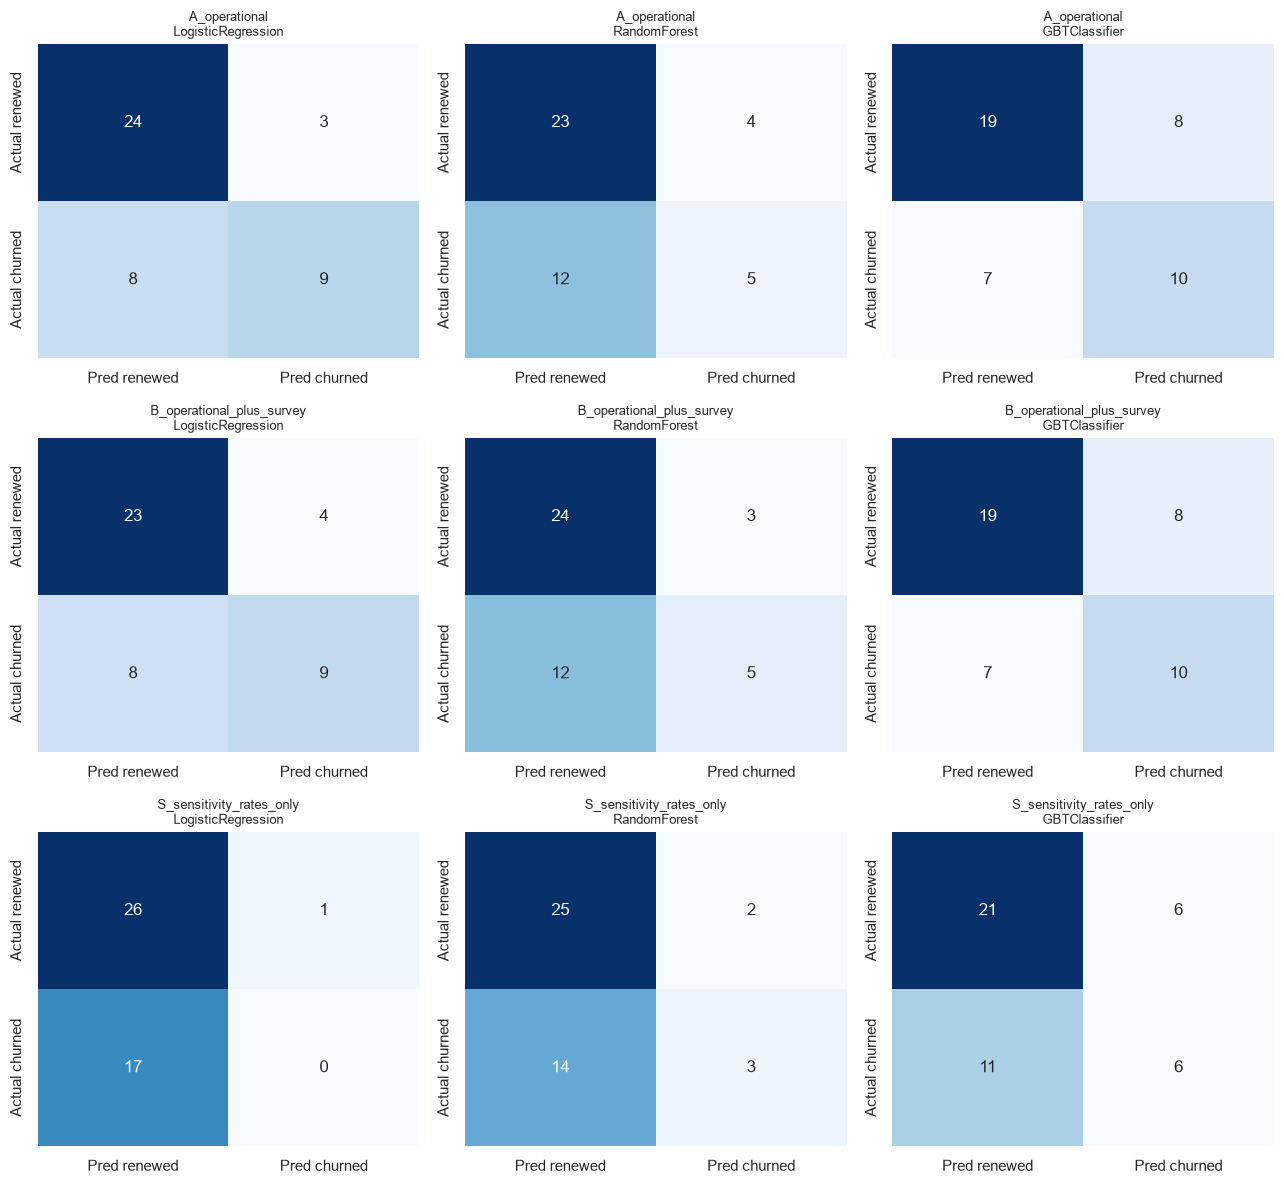

In [11]:
fig, axes = plt.subplots(len(CONFIGS), 3, figsize=(13, 4 * len(CONFIGS)))
for i, cfg_name in enumerate(CONFIGS):
    for j, model_name in enumerate(["LogisticRegression", "RandomForest", "GBTClassifier"]):
        r = results_df[(results_df.config == cfg_name) & (results_df.model == model_name)].iloc[0]
        cm = np.array([[r.TN, r.FP], [r.FN, r.TP]])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i, j],
                    xticklabels=["Pred renewed", "Pred churned"], yticklabels=["Actual renewed", "Actual churned"])
        axes[i, j].set_title(f"{cfg_name}\n{model_name}", fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=130)
plt.show()

## 9. Model comparison: A versus B (and sensitivity S)

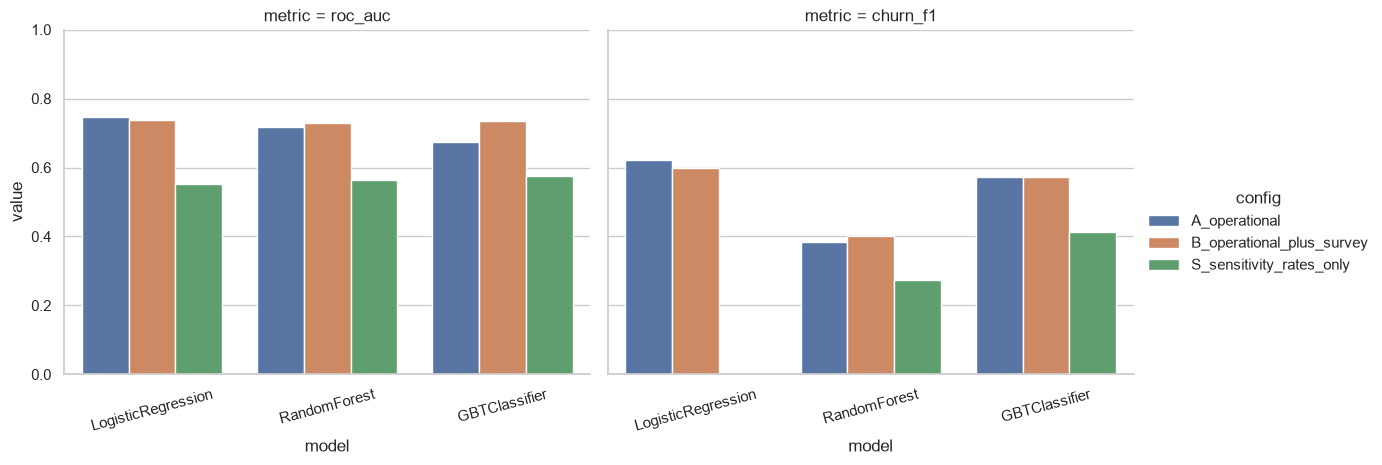

config,A_operational,B_operational_plus_survey,B_minus_A
model,,,
GBTClassifier,0.675,0.734,0.059
LogisticRegression,0.747,0.739,-0.009
RandomForest,0.717,0.730,0.013


One test customer changes accuracy by 2.27 percentage points, so differences of one or two customers are noise.


In [12]:
plot_df = results_df.melt(id_vars=["config", "model"], value_vars=["roc_auc", "churn_f1"], var_name="metric", value_name="value")
g = sns.catplot(data=plot_df, x="model", y="value", hue="config", col="metric", kind="bar",
                height=4.5, aspect=1.3, sharey=True)
g.set_xticklabels(rotation=15)
g.set(ylim=(0, 1))
g.savefig(OUTPUT_DIR / "model_comparison.png", dpi=130)
plt.show()

a_vs_b = (results_df.pivot(index="model", columns="config", values="roc_auc")
          [["A_operational", "B_operational_plus_survey"]])
a_vs_b["B_minus_A"] = a_vs_b["B_operational_plus_survey"] - a_vs_b["A_operational"]
display(a_vs_b.round(3))
print("One test customer changes accuracy by", round(100 / n_test, 2), "percentage points, so differences of one or two customers are noise.")

## 10. ROC curves

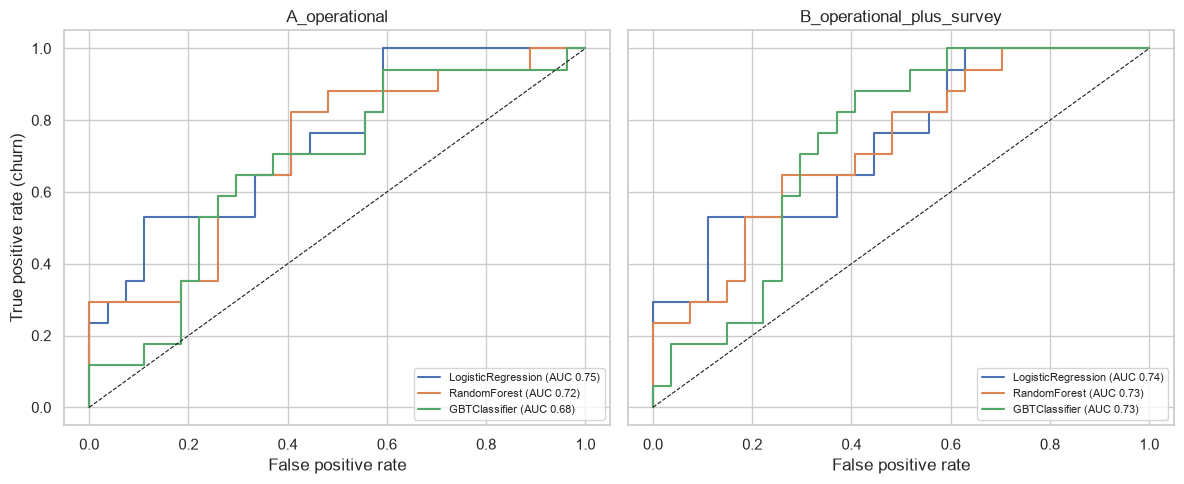

In [13]:
def roc_points(pred):
    # PySpark 4.3 exposes only the AUC on BinaryClassificationMetrics, so the ROC
    # points are built in Spark: sort by churn score and take cumulative counts.
    p = pred.select(vector_to_array("probability")[1].alias("score"), F.col("churn_label").alias("y"))
    n_pos = p.filter(F.col("y") == 1.0).count()
    n_neg = p.count() - n_pos
    w = Window.orderBy(F.desc("score")).rowsBetween(Window.unboundedPreceding, Window.currentRow)
    cum = (p.withColumn("tp", F.sum("y").over(w))
            .withColumn("fp", F.sum(F.lit(1.0) - F.col("y")).over(w))
            .select((F.col("fp") / n_neg).alias("fpr"), (F.col("tp") / n_pos).alias("tpr"))
            .toPandas().sort_values(["fpr", "tpr"]))
    return [(0.0, 0.0)] + list(zip(cum["fpr"], cum["tpr"])) + [(1.0, 1.0)]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, cfg_name in zip(axes, ["A_operational", "B_operational_plus_survey"]):
    for model_name in ["LogisticRegression", "RandomForest", "GBTClassifier"]:
        _, pred = fitted[(cfg_name, model_name)]
        pts = roc_points(pred)
        fpr, tpr = zip(*pts)
        auc = results_df[(results_df.config == cfg_name) & (results_df.model == model_name)].roc_auc.iloc[0]
        ax.plot(fpr, tpr, label=f"{model_name} (AUC {auc:.2f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
    ax.set_title(cfg_name)
    ax.set_xlabel("False positive rate")
    ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("True positive rate (churn)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=130)
plt.show()

## 11. Final model selection and saving

The final model is chosen by **cross-validated** AUC among Configurations A and B only. The test set is not used for selection. Configuration S is reported for sensitivity and is not a candidate.

In [14]:
required = results_df[results_df.config.isin(["A_operational", "B_operational_plus_survey"])]
best = required.sort_values("cv_roc_auc", ascending=False).iloc[0]
print("Selected by CV AUC:", best.config, "/", best.model, "| CV AUC", round(best.cv_roc_auc, 3), "| test AUC", round(best.roc_auc, 3))
best_cv_model, _ = fitted[(best.config, best.model)]
best_pipeline = best_cv_model.bestModel
best_pipeline.write().overwrite().save(str(MODEL_DIR / f"best_pipeline_{best.config}_{best.model}"))
print("Saved to:", MODEL_DIR / f"best_pipeline_{best.config}_{best.model}")

split_table.to_csv(OUTPUT_DIR / "split_class_distribution.csv")

Selected by CV AUC: A_operational / LogisticRegression | CV AUC 0.776 | test AUC 0.747


Saved to: /Users/atchyuthkarri/7COM2005-Data-Engineering/PerfectPetClub/models/best_pipeline_A_operational_LogisticRegression


## 12. Conclusions

**Primary limitation: prediction-time leakage.** The ETL features cover each subscription's full window, which for churned customers ends at cancellation. The numbers below describe how well these features separate the classes. They do not show how well renewal could be predicted before the decision. The fix is implemented in [03](03_Fixed_Cutoff_Features.ipynb) and [04](04_Cutoff_Machine_Learning.ipynb) without changing the ETL. Those results are weaker: no model reaches a CV AUC above 0.60.

**Best model under the required configurations (selected by 3-fold CV AUC):** Configuration A, Logistic Regression (CV AUC 0.776, test AUC 0.747, churn precision 0.750, churn recall 0.529, churn F1 0.621, accuracy 0.750). On the 17 churned customers in the test set it found 9 and raised 3 false alarms.

**Churn identification trade-off:** Gradient-boosted trees have the highest churn recall (0.588, 10 of 17) but lower precision (0.556, 8 false alarms). Random Forest has the lowest recall (0.294). The choice depends on whether a missed churner or a wasted retention offer costs more; the notebook does not decide that.

**Impact of survey features (Configuration B vs A):** CV AUC is lower with the survey features for all three models (LR 0.767 vs 0.776, RF 0.711 vs 0.717, GBT 0.696 vs 0.707). Test AUC moves in both directions (LR -0.009, RF +0.013, GBT +0.059). One test customer changes accuracy by 2.27 points, so these differences are noise. The survey adds no consistent value.

**Leakage check (Configuration S):** When `duration_days` and raw totals are removed, the models fall to CV AUC 0.62 to 0.64 and test AUC 0.55 to 0.58, close to chance. Most of the apparent performance in A comes from features that depend on subscription length and the outcome window. The results in A and B should not be read as a forecast of renewal before the decision.

**Limitations**

- 221 customers and a 44-customer test set. Metrics move by several points with one or two customers, so no model can be called clearly better than another here.
- The label is a proxy: `auto_renew = 0` is treated as churn. Actual cancellation was not verified independently.
- Features cover each subscription's full window, which for churned customers ends at cancellation. Activity near the decision is included (17.7% of churned customers' orders fall in the final 30 days, against 7.4% for renewed).
- Survey timing is unknown, and Q3 (`satisfaction_score`) has the same wording as Q2 in the questionnaire.
- Zeros in the survey are kept as valid answers (assumption A). Treating them as missing was not tested.
- CV folds are random, not stratified (Spark's `CrossValidator` has no stratified option). The imputer and encoders are fitted inside each training fold, so nothing from the validation fold leaks into preprocessing.
- The default 0.5 decision threshold was used and not tuned. Calibration was not checked.

**Before any production use:** rebuild features at a fixed cutoff before each renewal decision (requires an ETL change); verify churn against actual cancellation records; validate on a time-based holdout or new customers; collect survey timestamps; and repeat the comparison on more data.

In [15]:
spark.stop()
print("SparkSession stopped.")

SparkSession stopped.
